# PlantLeafNet — Dataset Exploration & Preprocessing

This notebook combines **01_dataset_exploration.ipynb** and **02_data_preprocessing.ipynb** into one reproducible workflow.

## Objectives
1. Download and inspect the PlantVillage color-image dataset.
2. Explore class distribution, image dimensions, color modes, and corrupted files.
3. Identify exact and visually similar duplicate candidates.
4. Remove confirmed identical-image duplicates and create a cleaning manifest.
5. Create stratified train, validation, and test splits.
6. Save split CSV files and estimate image-channel statistics from a reproducible training sample.

> **Dataset note:** The color, grayscale, and segmented directories are alternate representations of the dataset. This workflow uses only the `color` directory to avoid mixing representations.

## 1. Environment setup and dataset download

Add your Kaggle API token to Colab Secrets as `KAGGLE_API_TOKEN` and enable notebook access. Do not paste credentials directly into notebook cells.

In [ ]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get(
    "KAGGLE_API_TOKEN"
)

print("Kaggle credentials configured!")

Kaggle credentials configured!


In [ ]:
!pip install -q kaggle ImageHash
!kaggle --version

Kaggle CLI 2.0.2


In [ ]:
import os

DATA_DIR = "/content/PlantLeafNet"

os.makedirs(DATA_DIR, exist_ok=True)

print("Project directory created:", DATA_DIR)

Project directory created: /content/PlantLeafNet


In [ ]:
!kaggle datasets download \
    -d abdallahalidev/plantvillage-dataset \
    -p /content/PlantLeafNet

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:24<00:00, 90.5MB/s]



In [ ]:
import zipfile
from pathlib import Path

zip_files = list(Path(DATA_DIR).glob("*.zip"))
if not zip_files:
    raise FileNotFoundError(
        f"No dataset ZIP found in {DATA_DIR}. Run the Kaggle download cell first."
    )

zip_path = zip_files[0]
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("Dataset extracted successfully:", zip_path.name)

## 2. Locate the color-image directory and inspect classes

In [ ]:
import os
import random
import hashlib
from collections import Counter, defaultdict
from pathlib import Path

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

In [ ]:
BASE_DIR = Path("/content/PlantLeafNet")

colr_dirs = [p for p in BASE_DIR.rglob("color")
if p.is_dir()and any(x.is_dir() for x in p.iterdir())]

print("color dir is found: ",len(colr_dirs))

for path in colr_dirs:
  print(path)

color dir is found:  1
/content/PlantLeafNet/plantvillage dataset/color


In [ ]:
COLOR_DIR = colr_dirs[0]
print("Dataset path:", COLOR_DIR)

Dataset path: /content/PlantLeafNet/plantvillage dataset/color


In [ ]:
class_names= sorted([i.name for i in COLOR_DIR.iterdir() if i.is_dir()])
print("Total clasess: ", len(class_names))

Total clasess:  38


## 3. Class distribution

In [ ]:
image_extension = {".jpg",".jpeg",".png",".bmp"}

class_count=[]

for i in class_names:
  class_paath = COLOR_DIR/ i

  image = [ file for file in class_paath.rglob("*")
  if file.is_file() and file.suffix.lower() in image_extension]

  class_count.append({"Class": i,
                       "Image_Count": len(image)})

df = pd.DataFrame(class_count)
df = df.sort_values(by = "Image_Count",ascending=False).reset_index(drop=True)
df

,Class,Image_Count
0,Orange___Haunglongbing_(Citrus_greening),5507
1,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357
2,Soybean___healthy,5090
3,Peach___Bacterial_spot,2297
4,Tomato___Bacterial_spot,2127
5,Tomato___Late_blight,1909
6,Squash___Powdery_mildew,1835
7,Tomato___Septoria_leaf_spot,1771
8,Tomato___Spider_mites Two-spotted_spider_mite,1676
9,Apple___healthy,1645


In [ ]:
print("Total Images:", df["Image_Count"].sum())
print("Total Classes:", len(df))
print("Average Images per Class:",
      df["Image_Count"].mean())
print("Median Images per Class:",
      df["Image_Count"].median())
print("Minimum Images:",
      df["Image_Count"].min())
print("Maximum Images:",
      df["Image_Count"].max())

Total Images: 54305
Total Classes: 38
Average Images per Class: 1429.078947368421
Median Images per Class: 1092.5
Minimum Images: 152
Maximum Images: 5507


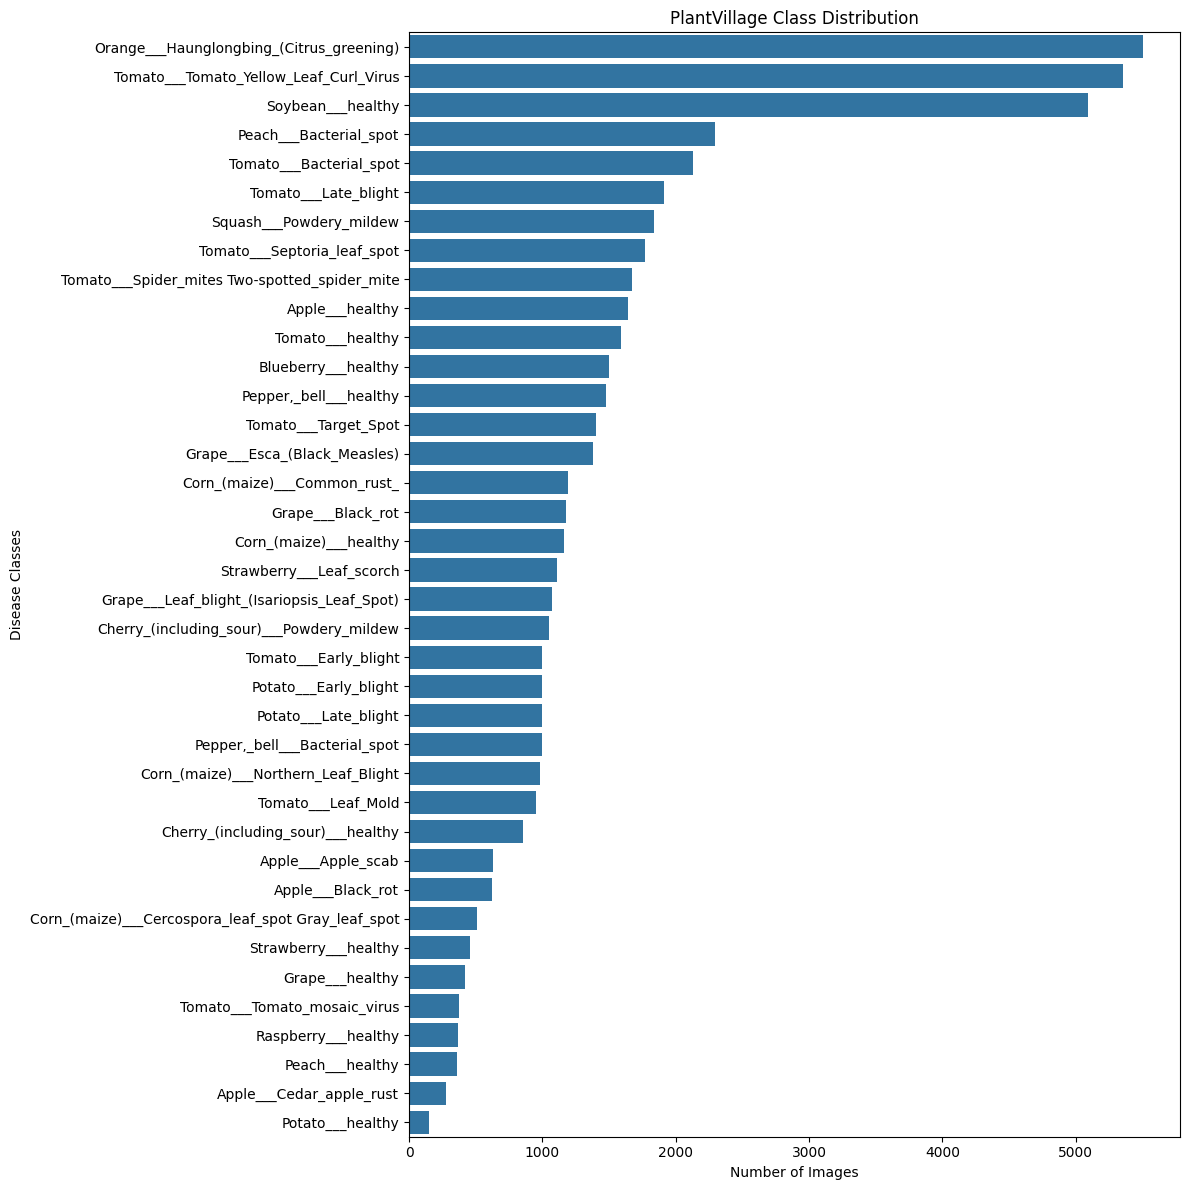

In [ ]:
plt.figure(figsize=(12, 12))

sns.barplot(
    data=df,
    x="Image_Count",
    y="Class"
)

plt.title("PlantVillage Class Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Disease Classes")

plt.tight_layout()
plt.show()

## 4. Visual sample inspection

In [ ]:
all_image_path=[
    file for class_name in class_names
    for file in (COLOR_DIR/class_name).rglob("*")
    if file.is_file() and file.suffix.lower() in image_extension
]

sample_images = random.sample(all_image_path,12)

plt.figure(figsize=(14,12))

for i , image_path in enumerate(sample_images):
  image = Image.open(image_path).convert("RGB")

  plt.subplot(3,4,i+1)
  plt.imshow(image)
  plt.title(image_path.parent.name,fontsize=8)
  plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Image quality and properties

Inspect image dimensions, color modes, and files that cannot be opened.

In [ ]:
dimension_count = Counter()
mode_count = Counter()
corrupted_images = []

for image_path in tqdm(all_image_path, desc="Inspecting images"):
    try:
        with Image.open(image_path) as img:
            dimension_count[img.size] += 1
            mode_count[img.mode] += 1
    except Exception:
        corrupted_images.append(str(image_path))

print("Most common image dimensions:")
print(dimension_count.most_common(10))
print("\nImage color modes:")
print(mode_count)
print("\nCorrupted images:", len(corrupted_images))

## 6. Exact duplicate detection using MD5

MD5 hashes identify byte-identical files. This does not detect images that contain the same visual content but have different encodings.

In [ ]:
import hashlib
from collections import defaultdict
from tqdm.auto import tqdm

In [ ]:
hash_groups = defaultdict(list)

for image_path in tqdm(all_image_path):
  try:
    with open (image_path,"rb") as f:
      file_hash= hashlib.md5(f.read()).hexdigest()
    hash_groups[file_hash].append(str(image_path))
  except Exception as e:
    print("Error: ", image_path,e)
duplicat_groups = {
    file_hash:paths
    for file_hash, paths in hash_groups.items()
    if len(paths)>1
}

print("Total images scanned:", len(all_image_path))
print("Unique file hashes:", len(hash_groups))
print("Duplicate groups:", len(duplicat_groups))

duplicat_image_count = sum( len(paths) for paths in duplicat_groups.values())
print("Images belonging to duplicate groups:", duplicat_image_count)

  0%|          | 0/54305 [00:00<?, ?it/s]

Total images scanned: 54305
Unique file hashes: 54284
Duplicate groups: 21
Images belonging to duplicate groups: 42


### Review exact duplicate groups

In [ ]:
cross_class_duplicates = []

for file_hash, paths in duplicat_groups.items():
    classes_in_group = {Path(path).parent.name for path in paths}
    if len(classes_in_group) > 1:
        cross_class_duplicates.append({
            "Hash": file_hash,
            "Classes": sorted(classes_in_group),
            "Files": paths
        })

print("Exact duplicate groups across different classes:",
      len(cross_class_duplicates))
for group in cross_class_duplicates:
    print("\nClasses:", group["Classes"])
    for path in group["Files"]:
        print(" ", path)

In [ ]:
duplicate_records = []
for file_hash, paths in duplicat_groups.items():
  for path in paths:
    duplicate_records.append({
            "MD5_Hash": file_hash,
            "Image_Path": path,
            "Class": Path(path).parent.name
        })
duplicates_df = pd.DataFrame(duplicate_records)

duplicates_df.to_csv("/content/PlantLeafNet/exact_duplicates.csv",
    index=False)
print("Saved:", len(duplicates_df), "duplicate records")

Saved: 42 duplicate records


## 7. Perceptual duplicate analysis

Perceptual hashing (pHash) finds visually similar images even when file encoding differs. Candidate pairs are not automatically duplicates; inspect samples before interpreting them. The Hamming-distance threshold below is 4.

In [ ]:
perceptual_hashes = {}
for image_path in tqdm(all_image_path):
  try:
    with Image.open(image_path) as img:
      img = img.convert("RGB")
      perceptual_hashes[str(image_path)] = imagehash.phash(img)
  except Exception as e:
        print("Error:", image_path, e)


  0%|          | 0/54305 [00:00<?, ?it/s]

In [ ]:
print("Images hashed:", len(perceptual_hashes))

Images hashed: 54305


In [ ]:
hash_to_paths = defaultdict(list)
for path, phash in perceptual_hashes.items():
  hash_to_paths[int(str(phash),16)].append(path)
print("Unique perceptual hashes:", len(hash_to_paths))

Unique perceptual hashes: 54283


In [ ]:
class BKTree:
    def __init__(self):
        self.root = None

    @staticmethod
    def distance(a, b):
        return (a ^ b).bit_count()

    def add(self, value):
        if self.root is None:
            self.root = (value, {})
            return

        node = self.root

        while True:
            current, children = node
            d = self.distance(value, current)

            if d in children:
                node = children[d]
            else:
                children[d] = (value, {})
                break

    def search(self, value, radius):
        results = []

        if self.root is None:
            return results

        stack = [self.root]

        while stack:
            current, children = stack.pop()
            d = self.distance(value, current)

            if d <= radius:
                results.append((d, current))

            for edge, child in children.items():
                if d - radius <= edge <= d + radius:
                    stack.append(child)

        return results

In [ ]:
tree = BKTree()

for phash_value in hash_to_paths:
    tree.add(phash_value)

candidate_pairs = set()
threshold = 4

for phash_value in hash_to_paths:
    matches = tree.search(phash_value, threshold)

    for distance, matched_hash in matches:
        if phash_value != matched_hash:
            pair = tuple(sorted((phash_value, matched_hash)))
            candidate_pairs.add(pair)

print("Near-duplicate candidate pairs:", len(candidate_pairs))

In [ ]:
near_duplicate_records = []

for hash_a, hash_b in candidate_pairs:
    for path_a in hash_to_paths[hash_a]:
        for path_b in hash_to_paths[hash_b]:
            near_duplicate_records.append({
                "Distance": (hash_a ^ hash_b).bit_count(),
                "Image_A": path_a,
                "Image_B": path_b,
                "Class_A": Path(path_a).parent.name,
                "Class_B": Path(path_b).parent.name
            })

near_duplicates_df = pd.DataFrame(near_duplicate_records)

near_duplicates_df = near_duplicates_df.sort_values(
    "Distance"
).reset_index(drop=True)

print("Candidate image pairs:", len(near_duplicates_df))
near_duplicates_df.head(20)

In [ ]:
# Count candidate pairs from different classes
cross_class_near_duplicates = near_duplicates_df[
    near_duplicates_df["Class_A"] != near_duplicates_df["Class_B"]
].copy()

same_class_near_duplicates = near_duplicates_df[
    near_duplicates_df["Class_A"] == near_duplicates_df["Class_B"]
].copy()

print("Total candidate pairs:", len(near_duplicates_df))
print("Same-class pairs:", len(same_class_near_duplicates))
print("Cross-class pairs:", len(cross_class_near_duplicates))

display(
    cross_class_near_duplicates
    .sort_values("Distance")
    .head(30)
)

Pair 1 | pHash distance: 2
Pair 2 | pHash distance: 2
Pair 3 | pHash distance: 2
Pair 4 | pHash distance: 2
Pair 5 | pHash distance: 2
Pair 6 | pHash distance: 2


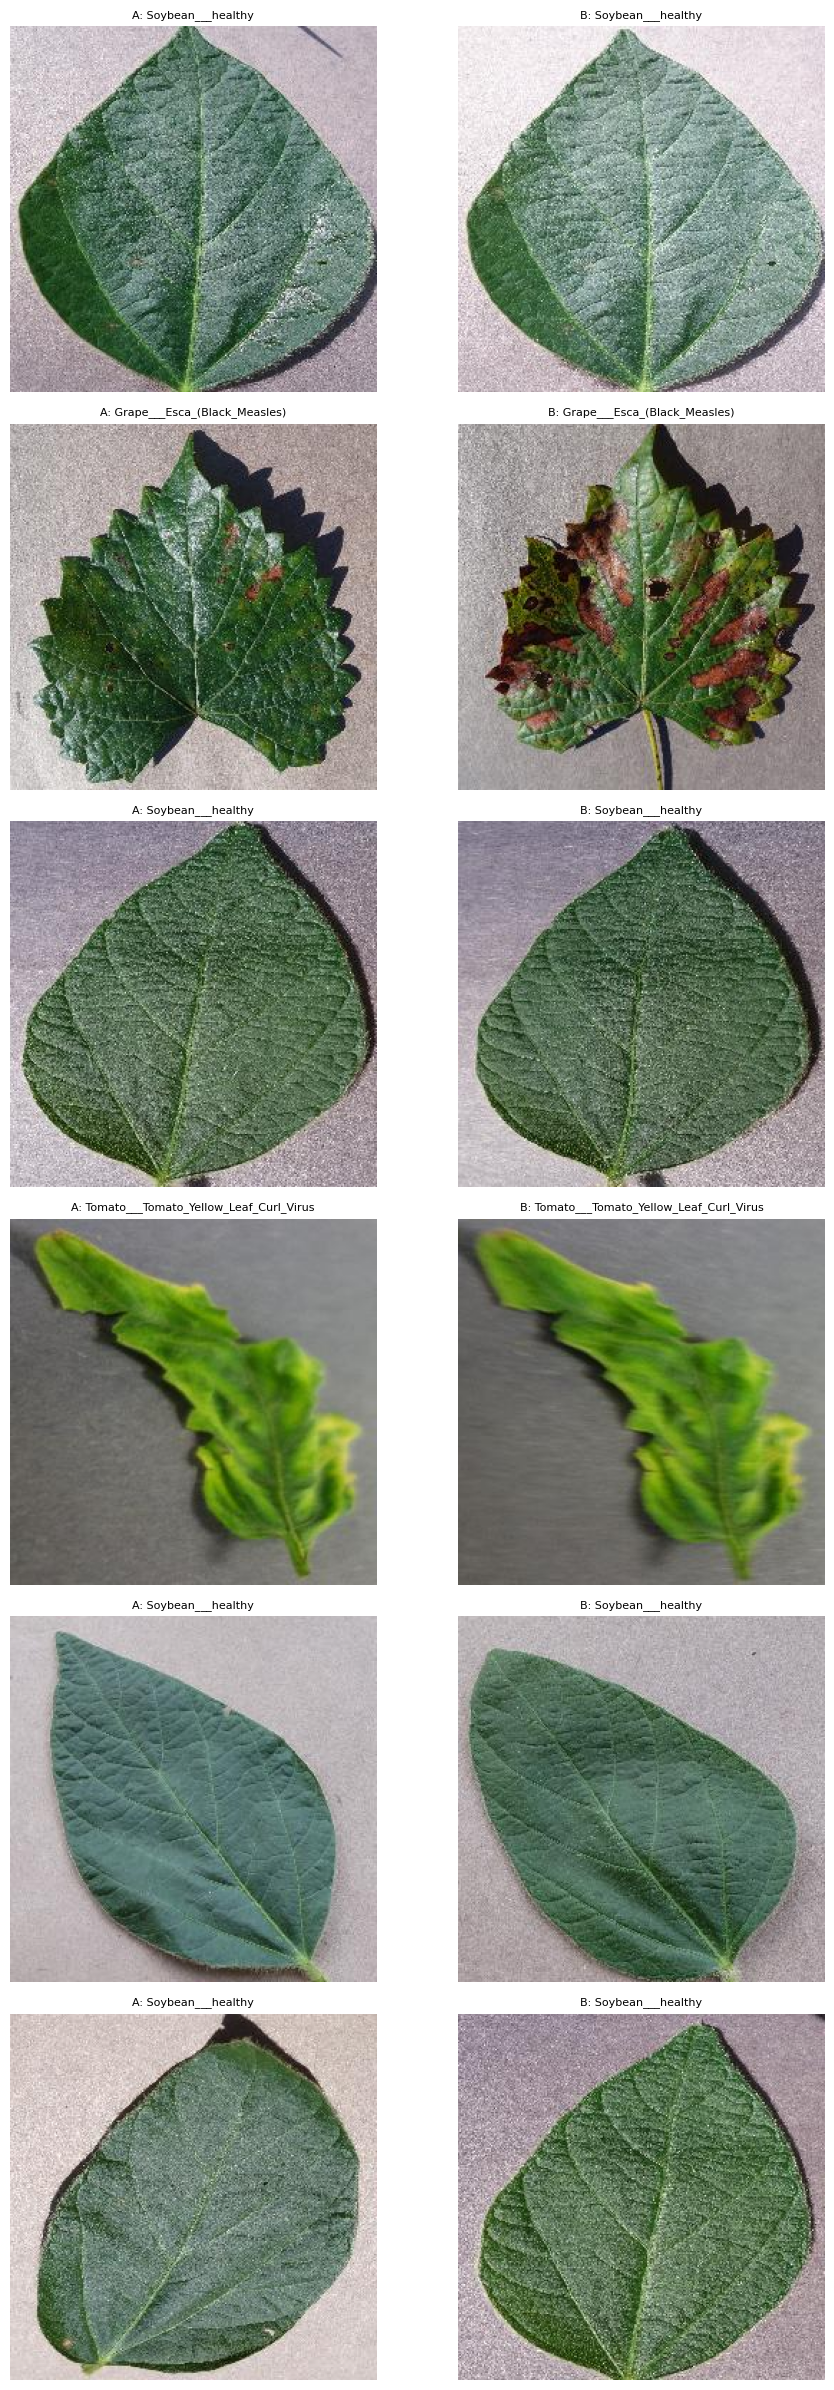

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

samples = near_duplicates_df.head(6)

fig, axes = plt.subplots(6, 2, figsize=(10, 24))

for i, (_, row) in enumerate(samples.iterrows()):

    img_a = Image.open(row["Image_A"]).convert("RGB")
    img_b = Image.open(row["Image_B"]).convert("RGB")

    axes[i, 0].imshow(img_a)
    axes[i, 0].set_title(
        f'A: {row["Class_A"]}', fontsize=8
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(img_b)
    axes[i, 1].set_title(
        f'B: {row["Class_B"]}', fontsize=8
    )
    axes[i, 1].axis("off")

    print(f"Pair {i+1} | pHash distance: {row['Distance']}")

plt.tight_layout()
plt.show()

In [ ]:
identical_phash_groups = {
    phash: paths
    for phash, paths in hash_to_paths.items()
    if len(paths) > 1
}

print("Groups with identical perceptual hashes:",
      len(identical_phash_groups))

print("Images in these groups:",
      sum(len(paths) for paths in identical_phash_groups.values()))

Groups with identical perceptual hashes: 22
Images in these groups: 44


In [ ]:
import hashlib
import pandas as pd

identical_hash_results = []

for phash, paths in identical_phash_groups.items():

    for path in paths:
        with open(path, "rb") as f:
            md5 = hashlib.md5(f.read()).hexdigest()

        identical_hash_results.append({
            "pHash": str(hex(phash)),
            "Class": Path(path).parent.name,
            "Path": path,
            "MD5": md5
        })

identical_hash_df = pd.DataFrame(identical_hash_results)

group_summary = (
    identical_hash_df
    .groupby("pHash")
    .agg(
        Files=("Path", "count"),
        Unique_MD5=("MD5", "nunique"),
        Class=("Class", "first")
    )
    .reset_index()
)

print(group_summary)

                 pHash  Files  Unique_MD5                   Class
0   0x8080a02b9abb6fff      2           2  Corn_(maize)___healthy
1   0x8cf171cd06c6732e      2           1        Tomato___healthy
2   0x8cf3f6ca1a0dc13c      2           1        Tomato___healthy
3   0x9931664c736639e6      2           1    Tomato___Late_blight
4   0x9be46d9238193c3e      2           1    Tomato___Late_blight
5   0x9cc7653836c6693c      2           1    Tomato___Late_blight
6   0xa4cd5b36169b5331      2           1    Tomato___Late_blight
7   0xacf693c985c93692      2           1        Tomato___healthy
8   0xad6bd21cdb92c413      2           1         Apple___healthy
9   0xad8e53b14cc65999      2           1    Tomato___Late_blight
10  0xade9d206d892d333      2           1         Apple___healthy
11  0xb412c90f9a69d33b      2           1         Apple___healthy
12  0xc1553fca32c43967      2           1    Tomato___Late_blight
13  0xc8b531867f49a45b      2           1        Tomato___healthy
14  0xc8e7

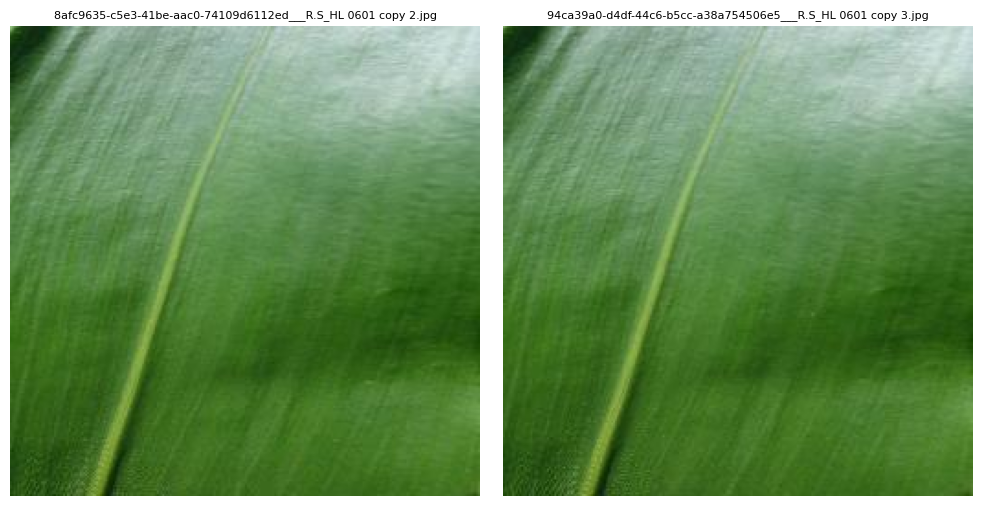

In [ ]:
corn_group = group_summary[
    group_summary["Unique_MD5"] > 1
]

for phash in corn_group["pHash"]:
    paths = identical_hash_df[
        identical_hash_df["pHash"] == phash
    ]["Path"].tolist()

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for ax, path in zip(axes, paths):
        ax.imshow(Image.open(path).convert("RGB"))
        ax.set_title(Path(path).name, fontsize=8)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
cross_class_near_duplicates = (
    near_duplicates_df[
        near_duplicates_df["Class_A"] !=
        near_duplicates_df["Class_B"]
    ]
    .sort_values("Distance")
    .reset_index(drop=True)
)

print("Cross-class candidate pairs:",
      len(cross_class_near_duplicates))

print(
    cross_class_near_duplicates[
        ["Distance", "Class_A", "Class_B"]
    ].head(20)
)

Cross-class candidate pairs: 300
    Distance                                        Class_A  \
0          2                              Soybean___healthy   
1          2                              Soybean___healthy   
2          2                              Soybean___healthy   
3          2                              Soybean___healthy   
4          2                              Soybean___healthy   
5          2                              Soybean___healthy   
6          4                            Raspberry___healthy   
7          4                           Tomato___Late_blight   
8          4                         Pepper,_bell___healthy   
9          4              Cherry_(including_sour)___healthy   
10         4                              Soybean___healthy   
11         4                         Pepper,_bell___healthy   
12         4                            Raspberry___healthy   
13         4                            Raspberry___healthy   
14         4          

Pair 1: Distance = 2
Pair 2: Distance = 2
Pair 3: Distance = 2
Pair 4: Distance = 2
Pair 5: Distance = 2
Pair 6: Distance = 2


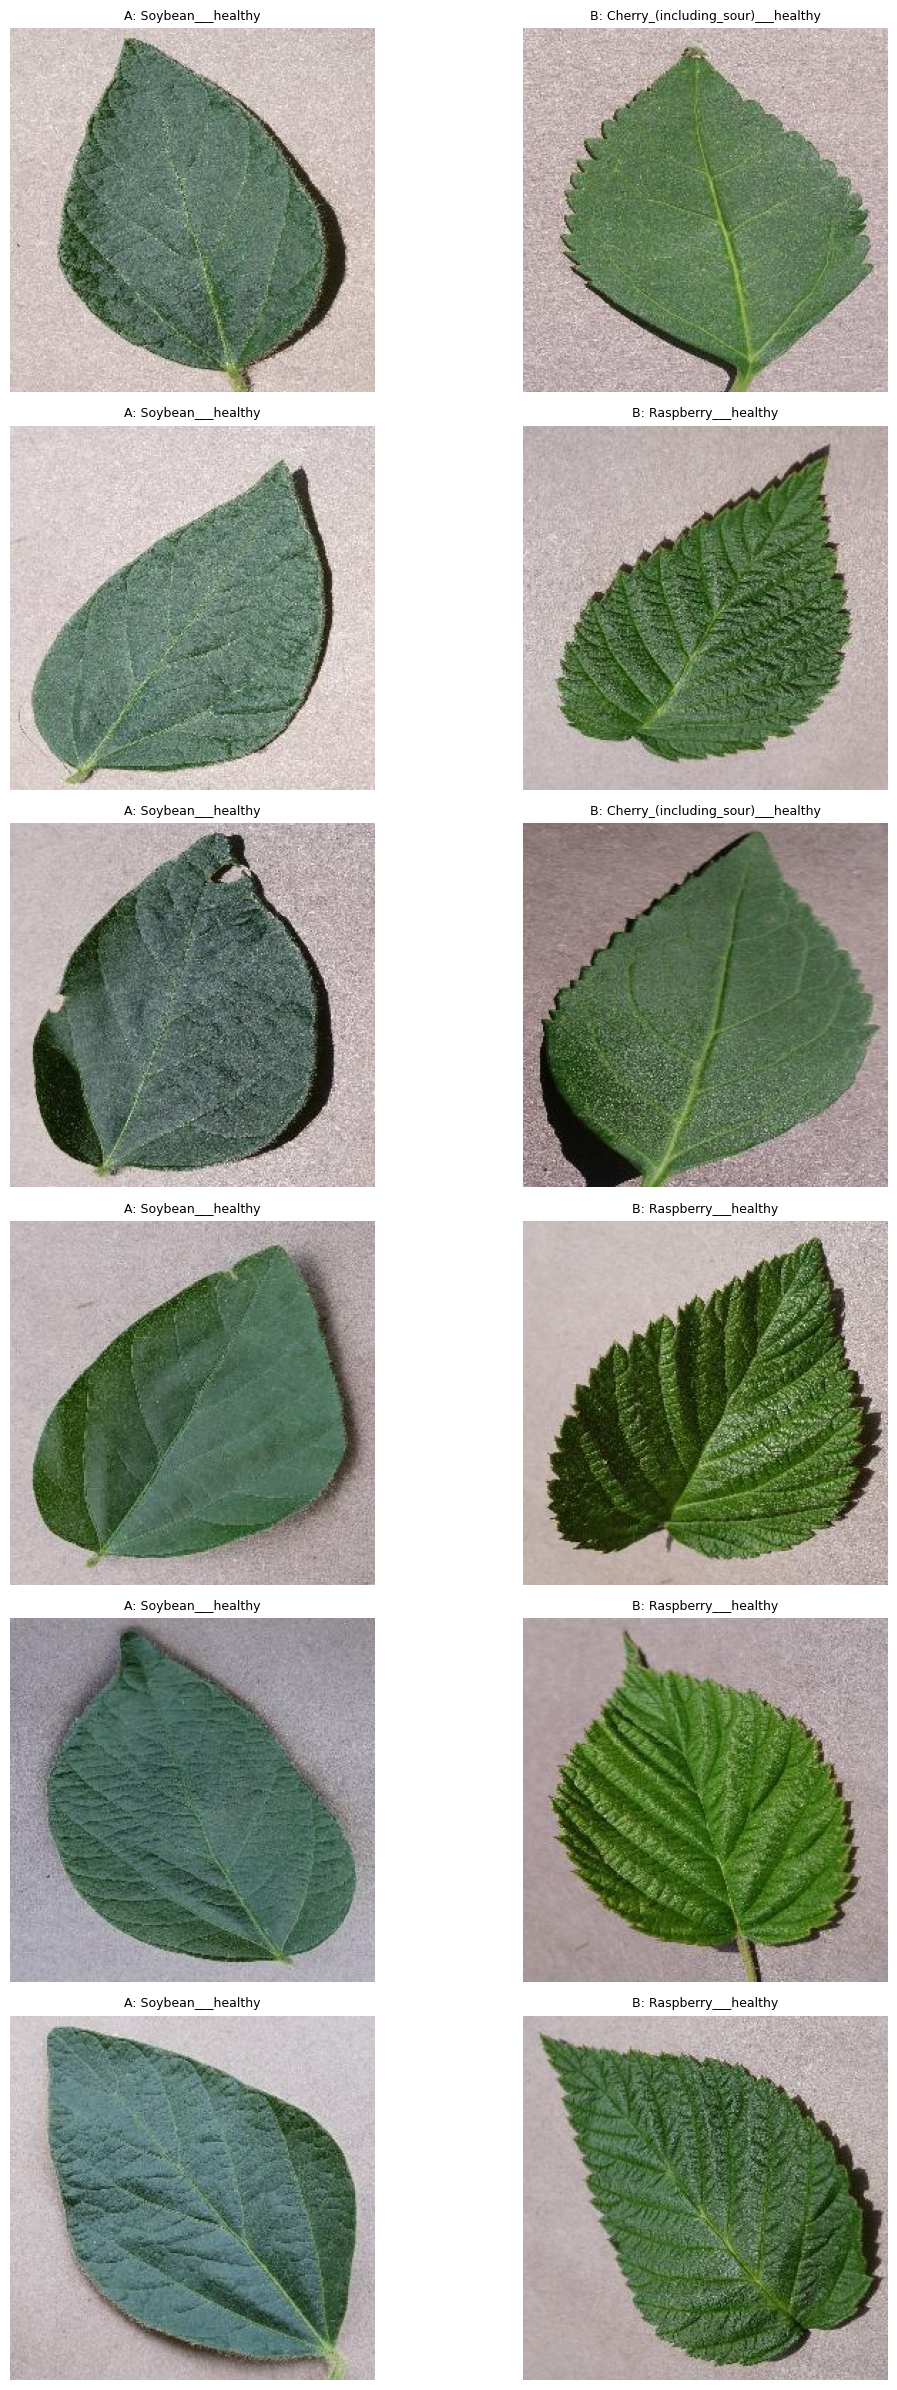

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

samples = cross_class_near_duplicates.head(6)

fig, axes = plt.subplots(6, 2, figsize=(12, 24))

for i, (_, row) in enumerate(samples.iterrows()):

    img_a = Image.open(row["Image_A"]).convert("RGB")
    img_b = Image.open(row["Image_B"]).convert("RGB")

    axes[i, 0].imshow(img_a)
    axes[i, 0].set_title(
        f'A: {row["Class_A"]}', fontsize=9
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(img_b)
    axes[i, 1].set_title(
        f'B: {row["Class_B"]}', fontsize=9
    )
    axes[i, 1].axis("off")

    print(f"Pair {i+1}: Distance = {row['Distance']}")

plt.tight_layout()
plt.show()

## 8. Remove identical pHash duplicates and create a cleaning manifest

The cleaning step keeps one deterministically selected image from each group with an identical pHash. Near-duplicate candidates with non-zero pHash distance are **not** automatically removed.

In [ ]:
duplicate_paths_to_remove = set()
duplicate_group_records = []

for group_id, (phash, paths) in enumerate(
    identical_phash_groups.items(), start=1
):
    # Deterministically keep the first sorted path
    sorted_paths = sorted(paths)
    keep_path = sorted_paths[0]

    for path in sorted_paths[1:]:
        duplicate_paths_to_remove.add(path)

    for path in sorted_paths:
        duplicate_group_records.append({
            "Group_ID": group_id,
            "pHash": str(hex(phash)),
            "Image_Path": path,
            "Decision": (
                "KEEP" if path == keep_path else "REMOVE"
            ),
            "Reason": "Confirmed same-photo duplicate group"
        })

cleaning_manifest = pd.DataFrame(duplicate_group_records)

cleaning_manifest.to_csv(
    "/content/PlantLeafNet/duplicate_cleaning_manifest.csv",
    index=False
)

print("Duplicate groups:", len(identical_phash_groups))
print("Images marked for removal:", len(duplicate_paths_to_remove))
print("Images remaining:", len(all_image_path) - len(duplicate_paths_to_remove))

Duplicate groups: 22
Images marked for removal: 22
Images remaining: 54283


In [ ]:
cleaned_image_paths = [
    path for path in all_image_path
    if str(path) not in duplicate_paths_to_remove
]

dataset_df = pd.DataFrame({
    "Image_Path": [str(path) for path in cleaned_image_paths],
    "Class": [Path(path).parent.name for path in cleaned_image_paths]
})

print("Cleaned dataset:", len(dataset_df))
print("Number of classes:", dataset_df["Class"].nunique())
print("Missing values:")
print(dataset_df.isnull().sum())

Cleaned dataset: 54283
Number of classes: 38
Missing values:
Image_Path    0
Class         0
dtype: int64


In [ ]:
dataset_df.to_csv(
    "/content/PlantLeafNet/cleaned_dataset.csv",
    index=False
)

In [ ]:
cleaned_counts = (
    dataset_df["Class"]
    .value_counts()
    .sort_values()
)

print("Classes:", len(cleaned_counts))
print("Total images:", cleaned_counts.sum())
print("\nSmallest classes:")
print(cleaned_counts.head(5))

print("\nLargest classes:")
print(cleaned_counts.tail(5))

Classes: 38
Total images: 54283

Smallest classes:
Class
Potato___healthy                152
Apple___Cedar_apple_rust        275
Peach___healthy                 360
Raspberry___healthy             371
Tomato___Tomato_mosaic_virus    373
Name: count, dtype: int64

Largest classes:
Class
Tomato___Bacterial_spot                     2127
Peach___Bacterial_spot                      2297
Soybean___healthy                           5090
Tomato___Tomato_Yellow_Leaf_Curl_Virus      5357
Orange___Haunglongbing_(Citrus_greening)    5507
Name: count, dtype: int64


## 9. Stratified train / validation / test split

Use a fixed random seed and stratification by class to preserve class proportions. The target split is 70% training, 15% validation, and 15% testing.

In [ ]:
from sklearn.model_selection import train_test_split
# first we have to split thae data in to 2 (train : 70 and temp :30(val:15,train15))
train_df,tem_df = train_test_split(dataset_df,test_size=0.30,random_state=42,stratify=dataset_df['Class'])
# now we have to split the temp to val 15 and test 15
val_df,test_df = train_test_split(tem_df,test_size=0.50,random_state=42,stratify=tem_df["Class"])

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("\nTotal:", len(train_df) + len(val_df) + len(test_df))

Training images: 37998
Validation images: 8142
Testing images: 8143

Total: 54283


In [ ]:
# Verify the split
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}")
    print("Images:", len(df))
    print("Classes:", df["Class"].nunique())
    print("Missing values:", df.isnull().sum().sum())


Train
Images: 37998
Classes: 38
Missing values: 0

Validation
Images: 8142
Classes: 38
Missing values: 0

Test
Images: 8143
Classes: 38
Missing values: 0


In [ ]:
# verify that there is no file overlap:
train_paths = set(train_df["Image_Path"])
val_paths = set(val_df["Image_Path"])
test_paths = set(test_df["Image_Path"])

print("Train-Val overlap:", len(train_paths & val_paths))
print("Train-Test overlap:", len(train_paths & test_paths))
print("Val-Test overlap:", len(val_paths & test_paths))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [ ]:
split_dir = Path("/content/PlantLeafNet/splits")
split_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(split_dir / "train.csv", index=False)
val_df.to_csv(split_dir / "validation.csv", index=False)
test_df.to_csv(split_dir / "test.csv", index=False)

print("All split files saved!")

All split files saved!


In [ ]:
split_distribution = pd.DataFrame({
    "Train": train_df["Class"].value_counts(),
    "Validation": val_df["Class"].value_counts(),
    "Test": test_df["Class"].value_counts()
}).fillna(0).astype(int)

display(split_distribution)

,Train,Validation,Test
Class,,,
Apple___Apple_scab,441,95,94
Apple___Black_rot,435,93,93
Apple___Cedar_apple_rust,193,41,41
Apple___healthy,1147,245,246
Blueberry___healthy,1051,225,226
Cherry_(including_sour)___Powdery_mildew,736,158,158
Cherry_(including_sour)___healthy,598,128,128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,359,77,77
Corn_(maize)___Common_rust_,834,179,179


## 10. Estimate image-channel statistics

Estimate per-image RGB means and standard deviations from a reproducible sample of up to 1,000 training images. These are descriptive dataset statistics; pretrained torchvision models should still use their own documented normalization transforms when required.

In [ ]:
# Reproducible sample
sample_df = train_df.sample(
    n=min(1000, len(train_df)),
    random_state=42
)

channel_means = []
channel_stds = []

for path in tqdm(sample_df["Image_Path"]):
    with Image.open(path) as img:
        img = img.convert("RGB").resize((224, 224))

        image_array = np.asarray(img, dtype=np.float32) / 255.0

        channel_means.append(
            image_array.mean(axis=(0, 1))
        )

        channel_stds.append(
            image_array.std(axis=(0, 1))
        )

channel_means = np.array(channel_means)
channel_stds = np.array(channel_stds)

print("Mean RGB:", channel_means.mean(axis=0))
print("Std RGB:", channel_stds.mean(axis=0))

  0%|          | 0/1000 [00:00<?, ?it/s]

Mean RGB: [0.4663161  0.48873132 0.41003904]
Std RGB: [0.17407656 0.14586209 0.19077277]


## 11. Outputs produced

This notebook saves the following artifacts under `/content/PlantLeafNet/`:

- `exact_duplicates.csv`
- `duplicate_cleaning_manifest.csv`
- `cleaned_dataset.csv`
- `splits/train.csv`
- `splits/validation.csv`
- `splits/test.csv`

## Conclusion

The notebook performs dataset-level exploration, duplicate investigation, cleaning, stratified splitting, and basic preprocessing-statistics estimation. It does not train a model; CNN baseline training is handled in `03_cnn_baseline.ipynb`, and transfer learning is handled in `04_transfer_learning.ipynb`.

**Reproducibility:** Run the cells from top to bottom in a fresh Colab runtime. Ensure Kaggle credentials are configured and the dataset has been downloaded before proceeding.